# PT Sinar Niaga Nusantara — Sales Data: Inspection, Cleaning & Processing

**Key findings**
- The raw export is **not trustworthy as delivered**: 982 lines in IDR *thousands*, 190 duplicated transactions, 32 test rows, two date formats, mixed discount units, inconsistent labels, missing cost/region, 8 implausible quantities.
- Cleaned data: **7,087 valid lines** (7,079 used for analysis). **Net revenue IDR 56.9 bn, gross profit IDR 7.6 bn, margin 13.4 %.**
- **Main insight:** net revenue grew +13.2 % YoY but gross profit fell 9.6 % (margin 15.0 % → 12.0 %). Cause: from **1 Sep 2025**, 20-30 % discounts appear (max was 15 % before). They sell at a loss and sit only in the **Online channel** and **3 Jawa Timur reps (SR07-SR09)**.

- Data mentah yang diekspor: terdapat 982 baris dengan nilai dalam *ribuan* IDR, 190 transaksi ganda, 32 baris uji coba, dua format tanggal, satuan diskon yang beragam, label yang tidak konsisten, data biaya/wilayah yang hilang, serta 8 jumlah (kuantitas) yang tidak masuk akal.
- Data setelah dibersihkan: **7.087 baris valid** (7.079 di antaranya digunakan untuk analisis). **Net revenue IDR 56,9 miliar, Gross profit IDR 7,6 miliar, Margin 13,4%.**
- **Main insight:** Net revenue tumbuh +13,2% secara tahunan, namun Gross profit justru turun 9,6% (margin turun dari 15,0% menjadi 12,0%). Penyebabnya: mulai **1 September 2025**, muncul diskon sebesar 20–30% (sebelumnya maksimal hanya 15%). Penjualan ini dilakukan dengan kondisi rugi dan hanya terjadi pada **Online Channel** serta melalui **3 perwakilan di Jawa Timur (SR07–SR09)**.

Reads `sales_transactions_raw.csv` and writes to `cleaned_output/`.

## 1. Load

In [22]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
pd.options.display.float_format = "{:,.2f}".format

RAW_PATH = next(p for p in [Path("sales_transactions_raw.csv"), Path("D:\Penta Sinergi\sales_transactions_raw.csv")] if p.exists())
OUT_DIR = Path("cleaned_output"); OUT_DIR.mkdir(exist_ok=True)
raw = pd.read_csv(RAW_PATH)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

7,309 rows x 15 columns


## 2. Inspection

Pemeriksaan dilakukan pada raw data, sehingga dapat menghitung data duplikat.

In [23]:
is_iso = raw["order_date"].str.fullmatch(r"\d{4}-\d{2}-\d{2}")
parts = raw.loc[~is_iso, "order_date"].str.split("/", expand=True).astype(int)
list_price = raw.groupby("product")["unit_price"].agg(lambda s: s.mode().iloc[0])
real = raw["customer_id"] != "TEST"
small_price = real & (raw["unit_price"] < raw["product"].map(list_price) / 100)
calc = raw["qty"] * raw["unit_price"] * (1 - raw["discount"])
calc_pct = raw["qty"] * raw["unit_price"] * (1 - raw["discount"].where(raw["discount"] <= 1, raw["discount"] / 100))
retail_big = (raw["customer_type"] == "Retail") & (raw["qty"].abs() > 5)

evidence = pd.DataFrame([
    ["Missing values", f"region {raw.region.isna().sum()}, cost {raw.cost.isna().sum()}"],
    ["Exact duplicate rows", f"{raw.duplicated().sum()} (every repeated order_id is an identical copy)"],
    ["Test records", f"{(~real).sum()} rows: customer TEST, rep dummy, price 0/1"],
    ["Label variants", f"region {raw.region.nunique()} spellings (6 real), channel {raw.channel.nunique()} (2), category {raw.category.nunique()} (6)"],
    ["Two date formats", f"{(~is_iso).sum()} rows dd/mm/yyyy; day>12 on {(parts[0] > 12).sum()} rows, month>12 on {(parts[1] > 12).sum()} -> day first"],
    ["Prices 1000x too small", f"{small_price.sum()} rows, all dd/mm/yyyy dates, from {raw.loc[small_price & ~is_iso, 'order_date'].str[-4:].min()}-04 onward"],
    ["Discount in percent", f"{(raw.discount > 1).sum()} rows (5..30 instead of 0.05..0.30); identity revenue=qty*price*(1-disc) fails on {((raw.revenue - calc).abs() > 1).sum()} rows as stored, {((raw.revenue - calc_pct).abs() > 1)[real].sum()} after fix"],
    ["Returns", f"{(raw.status == 'Returned').sum()} separate negative RET- lines; Cancelled lines still carry positive revenue"],
    ["Retail quantity outliers", f"{retail_big.sum()} Retail lines with 100-400 units (Retail max is otherwise 5)"],
], columns=["check", "finding"])
evidence

,check,finding
0,Missing values,"region 134, cost 520"
1,Exact duplicate rows,150 (every repeated order_id is an identical c...
2,Test records,"32 rows: customer TEST, rep dummy, price 0/1"
3,Label variants,"region 16 spellings (6 real), channel 5 (2), c..."
4,Two date formats,"1020 rows dd/mm/yyyy; day>12 on 530 rows, mont..."
5,Prices 1000x too small,"1006 rows, all dd/mm/yyyy dates, from 2026-04 ..."
6,Discount in percent,295 rows (5..30 instead of 0.05..0.30); identi...
7,Returns,135 separate negative RET- lines; Cancelled li...
8,Retail quantity outliers,8 Retail lines with 100-400 units (Retail max ...


In [24]:
# Order numbers are issued in time order, so dates must never go backwards. A block at the end breaks that.
def parse_dates(s):
    iso = s.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
    return pd.to_datetime(s.where(iso), format="%Y-%m-%d").fillna(pd.to_datetime(s.where(~iso), format="%d/%m/%Y"))
o = raw[raw["order_id"].str.match(r"^ORD-\d+$")].copy()
o["n"] = o["order_id"].str[4:].astype(int); o["d"] = parse_dates(o["order_date"]); o = o.sort_values("n")
back = o["d"].diff().dt.days < 0
print("order numbers dated earlier than the previous one:", int(back.sum()), "| all >= ORD-", int(o.loc[back, "n"].min()))
o[(o["n"] >= 106953) & (o["n"] <= 106959)][["order_id", "order_date", "customer_id", "product", "qty"]]

order numbers dated earlier than the previous one: 21 | all >= ORD- 106956


,order_id,order_date,customer_id,product,qty
7155,ORD-106953,2026-09-15,C01951,Smartphone Lumo A5,4
7156,ORD-106954,2026-09-15,C01879,Laptop Axio Pro 15,2
7157,ORD-106955,15/09/2026,C01101,Keyboard Mekanik K7,9
6077,ORD-106956,07/06/2026,C01424,Laptop Veno 13,1
1677,ORD-106957,2025-02-03,C02082,Kertas A4 80gsm (rim),4
7292,ORD-106958,2026-05-12,C02074,Tinta Botol Set CMYK,1
7118,ORD-106959,10/09/2026,C00634,Tinta Botol Set CMYK,2


## 3. Cleaning

**fix** hal yang terbukti benar berdasarkan data; **quarantine** hal yang tampak keliru namun tidak dapat dibuktikan; **delete** hanya entri yang bukan merupakan transaksi (data duplikat, data uji); **estimate** hanya jika kondisinya sangat mendesak, dan beri penanda khusus. Setiap langkah dicatat dalam `audit`.


In [25]:
df = raw.copy()
df["raw_line"] = np.arange(len(df)) + 2           # line number in the CSV, for traceability
audit = []
def log(step, rows, left): audit.append({"step": step, "rows_affected": int(rows), "rows_left": len(df) if left is None else left})

# 1) exact duplicates and test records
dup = df.drop(columns="raw_line").duplicated()
dupes_removed = df[dup]; df = df[~dup].copy(); log("Drop exact duplicates", dup.sum(), None)
test = df["customer_id"].eq("TEST") | df["sales_rep"].eq("dummy") | df["order_id"].str.match(r"^ORD-T\d+")
test_rows = df[test]; df = df[~test].copy(); log("Remove test records", test.sum(), None)

# 2) standardise labels
for c in ["region", "channel", "customer_id", "customer_type", "sales_rep", "category", "product", "status"]:
    df[c] = df[c].str.strip()
region_map = {"jakarta": "Jakarta", "dki jakarta": "Jakarta", "jkt": "Jakarta", "jawa barat": "Jawa Barat", "jabar": "Jawa Barat",
              "jawa timur": "Jawa Timur", "jatim": "Jawa Timur", "sumatera": "Sumatera", "sumatra": "Sumatera",
              "kalimantan": "Kalimantan", "sulawesi": "Sulawesi"}
n_missing_region = df["region"].isna().sum()
df["region"] = df["region"].str.lower().map(region_map)
assert df["region"].isna().sum() == n_missing_region
df["region"] = df["region"].fillna("Unknown")                      # revenue is real; region cannot be inferred
df["channel"] = df["channel"].str.lower().map({"online": "Online", "e-commerce": "Online", "offline": "Offline"})
df["category"] = df["product"].map(df.groupby("product")["category"].agg(lambda s: s.mode().iloc[0]))   # product -> category is 1:1
assert df["channel"].notna().all() and df["category"].nunique() == 6
log("Standardise region / channel / category", len(df), None)
print("rows:", len(df), "| regions:", df.region.nunique(), "| channels:", df.channel.nunique(), "| categories:", df.category.nunique())

rows: 7127 | regions: 7 | channels: 2 | categories: 6


In [26]:
# 3) dates: dd/mm/yyyy and yyyy-mm-dd  ->  parsing menjadi yyyy-mm-dd
raw_date = df["order_date"].copy()
is_iso = raw_date.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
df["order_date"] = pd.to_datetime(raw_date.where(is_iso), format="%Y-%m-%d").fillna(pd.to_datetime(raw_date.where(~is_iso), format="%d/%m/%Y"))
log("Parse dd/mm/yyyy dates to yyyy-mm-dd", (~is_iso).sum(), None)
pd.DataFrame({"before (dd/mm/yyyy)": raw_date[~is_iso], "after (yyyy-mm-dd)": df.loc[~is_iso, "order_date"].dt.strftime("%Y-%m-%d")}).head(5)

,before (dd/mm/yyyy),after (yyyy-mm-dd)
5445,01/04/2026,2026-04-01
5446,01/04/2026,2026-04-01
5447,01/04/2026,2026-04-01
5448,01/04/2026,2026-04-01
5449,01/04/2026,2026-04-01


In [27]:
# 4) IDR-thousand rows (x1000) and discount in percent (/100); proof: revenue = qty x price x (1 - discount) on EVERY row
list_price = df.groupby("product")["unit_price"].agg(lambda s: s.mode().iloc[0])
ratio = df["unit_price"] / df["product"].map(list_price)
scale = pd.Series(np.where(np.isclose(ratio, 0.001), 1000, np.where(np.isclose(ratio, 1), 1, np.nan)), index=df.index)
assert scale.notna().all()
rescaled = scale.eq(1000)
for c in ["unit_price", "revenue", "cost"]:
    df[c] = df[c] * scale
df["scale_fixed"] = rescaled
pct = df["discount"] > 1
df.loc[pct, "discount"] = df.loc[pct, "discount"] / 100
err = (df["revenue"] - df["qty"] * df["unit_price"] * (1 - df["discount"])).abs().max()
assert err < 1 and df["discount"].between(0, 1).all()
log("Rescale IDR-thousand rows x1000", rescaled.sum(), None); log("Convert discount percent -> fraction", pct.sum(), None)
print(f"rescaled {rescaled.sum()} rows (identical to the dd/mm/yyyy rows: {bool((rescaled == ~is_iso).all())}) | discount fixed {pct.sum()} | max revenue error {err:.2f} IDR")

rescaled 982 rows (identical to the dd/mm/yyyy rows: True) | discount fixed 293 | max revenue error 0.00 IDR


In [28]:
# 5) re-keyed duplicates: same transaction under a new order_id (ids 106955-106994); only cost differs slightly
dup_key = ["order_date", "region", "channel", "customer_id", "customer_type", "sales_rep", "category", "product",
           "qty", "discount", "status", "unit_price", "revenue"]
df["order_no"] = df["order_id"].str[4:].astype(int)
df = df.sort_values(["order_no", "raw_line"])
rk = df.duplicated(subset=dup_key, keep="first")
rekeyed = df[rk]
pairs = rekeyed.merge(df[~rk], on=dup_key, suffixes=("_copy", "_orig"))
# a RET line points to ORD-<same number>; if that order was a copy, re-point the return to the surviving original
copy_to_orig = dict(zip(pairs["order_no_copy"], pairs["order_no_orig"]))
df["linked_no"] = np.where(df["order_id"].str.startswith("RET-"), df["order_no"].map(copy_to_orig).fillna(df["order_no"]), np.nan)
df = df[~rk].copy(); log("Drop re-keyed duplicate orders", rk.sum(), None)

seq = df[df["order_id"].str.startswith("ORD-")].sort_values("order_no")
print(f"re-keyed copies: {len(rekeyed)} (ids {rekeyed.order_no.min()}-{rekeyed.order_no.max()}) | dates going backwards now: {int((seq.order_date.diff().dt.days < 0).sum())}")
pairs[["order_id_copy", "order_id_orig", "order_date", "customer_id", "product", "qty", "cost_copy", "cost_orig"]].head(4)

re-keyed copies: 40 (ids 106955-106994) | dates going backwards now: 0


,order_id_copy,order_id_orig,order_date,customer_id,product,qty,cost_copy,cost_orig
0,ORD-106955,ORD-106944,2026-09-15,C01101,Keyboard Mekanik K7,9,"3,577,500.00","3,578,400.00"
1,ORD-106956,ORD-105953,2026-06-07,C01424,Laptop Veno 13,1,"5,524,400.00","5,526,200.00"
2,ORD-106957,ORD-101345,2025-02-03,C02082,Kertas A4 80gsm (rim),4,"152,000.00","150,000.00"
3,ORD-106958,ORD-105738,2026-05-12,C02074,Tinta Botol Set CMYK,1,"163,400.00","166,900.00"


In [29]:
# 6) returns reverse an existing order exactly -> verify, then fill missing cost
is_ord = df["order_id"].str.startswith("ORD-"); is_ret = df["status"].eq("Returned")
orig = df[is_ord].set_index("order_no")
ret_link = df.loc[is_ret, "linked_no"].fillna(df.loc[is_ret, "order_no"]).astype(int)
o_ = orig.reindex(ret_link.values)
assert (df.loc[is_ret, "qty"].values == -o_["qty"].values).all() and np.isclose(df.loc[is_ret, "revenue"].values, -o_["revenue"].values).all()
print(f"{is_ret.sum()} returns, all exact negatives of an existing Completed order")

# missing cost: product-year median unit cost x qty (unit cost is stable, std < 1 %); returns mirror the original's cost
df["year"] = df["order_date"].dt.year
known = df[is_ord & df["status"].eq("Completed") & df["cost"].notna()]
unit_cost = (known["cost"] / known["qty"]).groupby([known["product"], known["year"]]).median()
df["cost_source"] = np.where(df["cost"].notna(), "reported", "missing")
need = is_ord & df["status"].eq("Completed") & df["cost"].isna()
df.loc[need, "cost"] = [unit_cost[(p, y)] * q for p, y, q in zip(df.loc[need, "product"], df.loc[need, "year"], df.loc[need, "qty"])]
df.loc[need, "cost_source"] = "imputed (product-year median unit cost)"
df.loc[is_ret, "cost"] = -df.loc[is_ord].set_index("order_no")["cost"].reindex(ret_link.values).values
df.loc[is_ret, "cost_source"] = "mirrors original order"
df.loc[df["status"].eq("Cancelled"), "cost_source"] = "n/a (cancelled)"
log("Impute missing cost / mirror cost on returns", need.sum(), None)
print("imputed cost on", int(need.sum()), "completed lines =", round(df.loc[need, "revenue"].sum() / df.loc[is_ord & df.status.eq("Completed"), "revenue"].sum() * 100, 1), "% of completed revenue")

# 7) implausible quantities: Retail never exceeds 5 units otherwise -> quarantine (kept, excluded from analysis)
df["suspect_qty"] = df["customer_type"].eq("Retail") & (df["qty"].abs() > 5)
df["include_in_analysis"] = ~df["suspect_qty"]
log("Quarantine implausible Retail quantities", df["suspect_qty"].sum(), None)

clean = df.sort_values(["order_date", "order_no", "raw_line"]).reset_index(drop=True)[
    ["order_id", "order_date", "region", "channel", "customer_id", "customer_type", "sales_rep", "category", "product", "qty",
     "discount", "status", "unit_price", "revenue", "cost", "cost_source", "scale_fixed", "suspect_qty", "include_in_analysis", "raw_line"]]
pd.DataFrame(audit)

133 returns, all exact negatives of an existing Completed order


imputed cost on 483 completed lines = 4.4 % of completed revenue


,step,rows_affected,rows_left
0,Drop exact duplicates,150,7159
1,Remove test records,32,7127
2,Standardise region / channel / category,7127,7127
3,Parse dd/mm/yyyy dates to yyyy-mm-dd,982,7127
4,Rescale IDR-thousand rows x1000,982,7127
5,Convert discount percent -> fraction,293,7127
6,Drop re-keyed duplicate orders,40,7087
7,Impute missing cost / mirror cost on returns,483,7087
8,Quarantine implausible Retail quantities,8,7087


**Decisions in one line each:** dd/mm/yyyy terverifikasi melalui range 530 hari > 12 bulan dan nomor pesanan yang meningkat seiring tanggal. Baris data (dalam ribuan IDR) disesuaikan skalanya (identitas revenue terjaga pada 100% baris data). 40 entri duplikat dihapus, dengan satu transaksi return yang terkait dengannya dialihkan kembali ke data aslinya. Data region yang kosong diberi label `Unknown`. Data cost yang kosong diestimasi dan ditandai (mencakup 4,4% dari pendapatan). 8 baris data segmen Retail dengan volume 100–400 unit **quarantined (tidak dihapus)**. Ditemukan `customer_id` yang memiliki `customer_type` atau region berbeda pada baris data yang berbeda, karena tidak dapat diperbaiki, maka analisis dilakukan dengan menjadikan `customer_id` sebagai key utama.

## 4. Validation

In [30]:
chk = {
    "order_id unique": clean["order_id"].is_unique,
    "no missing values (cost only empty on cancelled)": clean.drop(columns="cost").notna().all().all() and clean.loc[clean.status != "Cancelled", "cost"].notna().all(),
    "7 regions / 2 channels / 6 categories": (clean.region.nunique(), clean.channel.nunique(), clean.category.nunique()) == (7, 2, 6),
    "qty > 0 except returns (< 0)": (clean.loc[clean.status != "Returned", "qty"] > 0).all() and (clean.loc[clean.status == "Returned", "qty"] < 0).all(),
    "revenue = qty x price x (1 - discount) on every row": ((clean.revenue - clean.qty * clean.unit_price * (1 - clean.discount)).abs() < 1).all(),
    "Online <-> SYS-ONLINE rep": ((clean.channel == "Online") == clean.sales_rep.eq("SYS-ONLINE")).all(),
    "order numbers rise with date": not (seq.order_date.diff().dt.days < 0).any(),
    "row bridge raw - removed = clean": len(raw) - len(dupes_removed) - len(test_rows) - len(rekeyed) == len(clean),
}
v = pd.Series(chk, name="passed").to_frame()
assert v["passed"].all()
v

,passed
order_id unique,True
no missing values (cost only empty on cancelled),True
7 regions / 2 channels / 6 categories,True
qty > 0 except returns (< 0),True
revenue = qty x price x (1 - discount) on every row,True
Online <-> SYS-ONLINE rep,True
order numbers rise with date,True
row bridge raw - removed = clean,True


## 5. Processing
- **Net revenue** = revenue dari data yang memiliki status `Completed` + `Returned` nilai pengembalian sudah dalam angka negatif, status `Cancelled` dihitung sebagai 0.
- **Gross profit** = net revenue − net cost (cost untuk barang `Returned` bernilai negatif, sehingga order menghasilkan pendapatan nol *sekaligus* zero profit).
- **Margin %** = Σ gross profit ÷ Σ net revenue (bukan average dari margin per data).
- Data Sep 2026 belum lengkap (hanya sampai tanggal 15).

In [31]:
a = clean.copy()
a["year"] = a["order_date"].dt.year; a["month"] = a["order_date"].dt.month; a["quarter"] = a["order_date"].dt.quarter
a["year_month"] = a["order_date"].dt.to_period("M").astype(str); a["year_quarter"] = a["year"].astype(str) + "-Q" + a["quarter"].astype(str)
counted = a["status"].isin(["Completed", "Returned"])
a["net_revenue"] = np.where(counted, a["revenue"], 0.0)
a["net_cost"] = np.where(counted, a["cost"], 0.0)
a["gross_profit"] = a["net_revenue"] - a["net_cost"]
a["gross_margin_pct"] = np.where(a["net_revenue"] != 0, a["gross_profit"] / a["net_revenue"].replace(0, np.nan) * 100, np.nan)

analysis = a[a["include_in_analysis"]].copy()
def summarise(g, by):
    t = g.groupby(by, observed=True).agg(net_revenue=("net_revenue", "sum"), gross_profit=("gross_profit", "sum"),
                                          order_lines=("status", lambda s: int((s == "Completed").sum())))
    t["margin_pct"] = t["gross_profit"] / t["net_revenue"] * 100
    return t
print(f"net revenue {analysis.net_revenue.sum():,.0f} | gross profit {analysis.gross_profit.sum():,.0f} | margin {analysis.gross_profit.sum() / analysis.net_revenue.sum() * 100:.1f}%")

net revenue 56,940,963,400 | gross profit 7,608,871,400 | margin 13.4%


### Table 1 · Monthly net revenue, gross profit, margin %

In [32]:
monthly = summarise(analysis, "year_month")
monthly["note"] = np.where(monthly.index == "2026-09", "partial month (to 15 Sep)", "")
monthly

,net_revenue,gross_profit,order_lines,margin_pct,note
year_month,,,,,
2024-09,"1,793,024,750.00","283,389,900.00",235,15.81,
2024-10,"1,777,732,000.00","256,750,300.00",223,14.44,
2024-11,"2,218,372,500.00","348,328,100.00",269,15.70,
2024-12,"2,551,674,250.00","351,833,150.00",331,13.79,
2025-01,"1,577,240,600.00","236,151,850.00",211,14.97,
2025-02,"1,967,634,350.00","293,172,500.00",243,14.90,
2025-03,"2,804,530,500.00","451,854,050.00",366,16.11,
2025-04,"1,763,232,250.00","255,871,550.00",202,14.51,
2025-05,"2,034,898,000.00","290,977,350.00",266,14.30,


### Table 2 · Net revenue and margin by region × category

In [33]:
region_category = summarise(analysis, ["region", "category"]).sort_values("net_revenue", ascending=False).reset_index()
region_category

,region,category,net_revenue,gross_profit,order_lines,margin_pct
0,Jakarta,Laptop,"6,273,775,000.00","377,683,700.00",324,6.02
1,Jawa Barat,Laptop,"5,345,430,000.00","260,986,900.00",246,4.88
2,Jawa Timur,Laptop,"4,282,690,000.00","150,815,100.00",219,3.52
3,Sumatera,Laptop,"3,710,390,000.00","203,772,500.00",163,5.49
4,Kalimantan,Laptop,"3,518,090,000.00","233,015,200.00",136,6.62
5,Jakarta,Smartphone,"2,923,200,000.00","231,079,900.00",325,7.91
6,Sulawesi,Laptop,"2,618,795,000.00","135,850,700.00",122,5.19
7,Jawa Barat,Smartphone,"2,184,085,000.00","179,221,700.00",231,8.21
8,Jawa Timur,Smartphone,"1,974,720,000.00","93,064,850.00",215,4.71
9,Jakarta,Peralatan Kantor,"1,964,411,450.00","551,743,650.00",294,28.09


### Table 3 · Top 10 customers by net revenue

In [34]:
cust = summarise(analysis, "customer_id")
cust["customer_type"] = analysis.groupby("customer_id")["customer_type"].agg(lambda s: s.mode().iloc[0])
cust["share_of_total_pct"] = cust["net_revenue"] / cust["net_revenue"].sum() * 100
top10 = cust.sort_values("net_revenue", ascending=False).head(10).reset_index()
top10.insert(0, "rank", range(1, 11))
top10[["rank", "customer_id", "customer_type", "order_lines", "net_revenue", "gross_profit", "margin_pct", "share_of_total_pct"]]

,rank,customer_id,customer_type,order_lines,net_revenue,gross_profit,margin_pct,share_of_total_pct
0,1,K0102,Korporat,1,"504,252,000.00","66,033,000.00",13.10,0.89
1,2,K0173,Korporat,7,"481,921,000.00","48,873,600.00",10.14,0.85
2,3,K0127,Korporat,5,"384,269,500.00","39,697,900.00",10.33,0.67
3,4,K0031,Korporat,7,"375,976,000.00","76,105,500.00",20.24,0.66
4,5,K0151,Korporat,7,"364,005,000.00","33,982,200.00",9.34,0.64
5,6,K0169,Korporat,5,"358,604,000.00","52,830,500.00",14.73,0.63
6,7,K0011,Korporat,6,"339,939,000.00","78,602,900.00",23.12,0.60
7,8,K0088,Korporat,6,"317,040,800.00","49,787,900.00",15.70,0.56
8,9,K0143,Korporat,12,"312,578,750.00","71,678,900.00",22.93,0.55
9,10,K0024,Korporat,6,"285,378,000.00","27,369,900.00",9.59,0.50


## 6. Insights

In [35]:
# Year on year on two full 12-month windows (Sep 2026 is partial and left out)
analysis["period"] = np.select([analysis.order_date < "2025-09-01", analysis.order_date < "2026-09-01"], ["Sep24-Aug25", "Sep25-Aug26"], "Sep26 partial")
yoy = summarise(analysis, "period").loc[["Sep24-Aug25", "Sep25-Aug26"], ["net_revenue", "gross_profit", "margin_pct"]]
yoy.loc["change"] = [yoy.net_revenue.pct_change().iloc[-1] * 100, yoy.gross_profit.pct_change().iloc[-1] * 100, yoy.margin_pct.diff().iloc[-1]]
yoy   # change row: % for revenue and profit, percentage points for margin

,net_revenue,gross_profit,margin_pct
period,,,
Sep24-Aug25,"26,123,657,450.00","3,912,426,850.00",14.98
Sep25-Aug26,"29,571,314,700.00","3,537,271,300.00",11.96
change,13.20,-9.59,-3.01


In [36]:
# Why? Margin by discount depth (completed lines)
comp = analysis[analysis.status == "Completed"].copy()
comp["gp"] = comp["revenue"] - comp["cost"]
comp["band"] = pd.cut(comp["discount"], [-0.001, 0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30], labels=["0%", "5%", "8-10%", "12-15%", "20%", "25%", "30%"])
by_band = comp.groupby("band", observed=True).agg(lines=("revenue", "size"), revenue=("revenue", "sum"), gross_profit=("gp", "sum"))
by_band["margin_pct"] = by_band["gross_profit"] / by_band["revenue"] * 100
print("first line with discount >= 20%:", comp.loc[comp.discount >= 0.20, "order_date"].min().date(), "| largest discount before:", comp.loc[comp.order_date < "2025-09-01", "discount"].max())
by_band

first line with discount >= 20%: 2025-09-01 | largest discount before: 0.15


,lines,revenue,gross_profit,margin_pct
band,,,,
0%,2958,"25,961,155,000.00","4,566,807,700.00",17.59
5%,1916,"15,449,113,750.00","2,083,872,700.00",13.49
8-10%,1074,"10,297,297,500.00","1,237,697,700.00",12.02
12-15%,195,"2,496,152,900.00","259,487,550.00",10.40
20%,198,"1,262,820,000.00","-17,546,900.00",-1.39
25%,206,"1,345,477,500.00","-140,219,550.00",-10.42
30%,191,"1,207,433,500.00","-224,432,750.00",-18.59


In [37]:
# Where? Only the Online channel and three Jawa Timur reps - and did it buy growth?
since = comp[comp.order_date >= "2025-09-01"].assign(deep=lambda d: d.discount >= 0.20)
where = since.groupby("channel").agg(lines=("deep", "size"), lines_20plus=("deep", "sum"))
where["share_%"] = where["lines_20plus"] / where["lines"] * 100
off = since[since.channel == "Offline"]
flag = off.groupby("sales_rep")["deep"].sum(); flag = flag[flag > 0].index.tolist()
print(where.round(1).to_string())
print("offline reps with any >=20% line:", flag, "| all in Jawa Timur:", bool((off[off.sales_rep.isin(flag)].region == "Jawa Timur").all()))

full = analysis[analysis.period != "Sep26 partial"]
ch = full.groupby(["channel", "period"])[["net_revenue", "gross_profit"]].sum().unstack("period")
growth = pd.DataFrame({"net_revenue_growth_%": (ch[("net_revenue", "Sep25-Aug26")] / ch[("net_revenue", "Sep24-Aug25")] - 1) * 100,
                       "gross_profit_growth_%": (ch[("gross_profit", "Sep25-Aug26")] / ch[("gross_profit", "Sep24-Aug25")] - 1) * 100})
print("\nGrowth by channel (the discounted channel did not grow):"); print(growth.round(1).to_string())

deep = comp[comp.discount >= 0.20]; below = comp[comp.gp < 0]
ltm2 = comp[(comp.order_date >= "2025-09-01") & (comp.order_date < "2026-09-01")]
d2 = ltm2[ltm2.discount >= 0.20]; rest = ltm2[ltm2.discount < 0.20]
print(f"\n>=20% discount lines: {len(deep)}, gross profit {deep.gp.sum():,.0f} | below-cost lines: {len(below)} ({len(below) / len(comp) * 100:.1f}%), loss {below.gp.sum():,.0f}")
print(f"Sep25-Aug26 margin without the >=20% lines: {rest.gp.sum() / rest.revenue.sum() * 100:.2f}% vs prior year {yoy.loc['Sep24-Aug25', 'margin_pct']:.2f}%")
print(f"Capping those {len(d2)} lines at 10% would add ~{(d2.qty * d2.unit_price * 0.9 - d2.cost).sum() - d2.gp.sum():,.0f} IDR gross profit (upper bound, volume held)")

         lines  lines_20plus  share_%
channel                              
Offline   2215           135     6.10
Online    1396           460    33.00
offline reps with any >=20% line: ['SR07', 'SR08', 'SR09'] | all in Jawa Timur: True

Growth by channel (the discounted channel did not grow):
         net_revenue_growth_%  gross_profit_growth_%
channel                                             
Offline                 21.70                  15.40
Online                  -0.50                 -55.10

>=20% discount lines: 595, gross profit -382,199,200 | below-cost lines: 382 (5.7%), loss -553,017,050
Sep25-Aug26 margin without the >=20% lines: 14.99% vs prior year 14.98%
Capping those 573 lines at 10% would add ~748,807,500 IDR gross profit (upper bound, volume held)


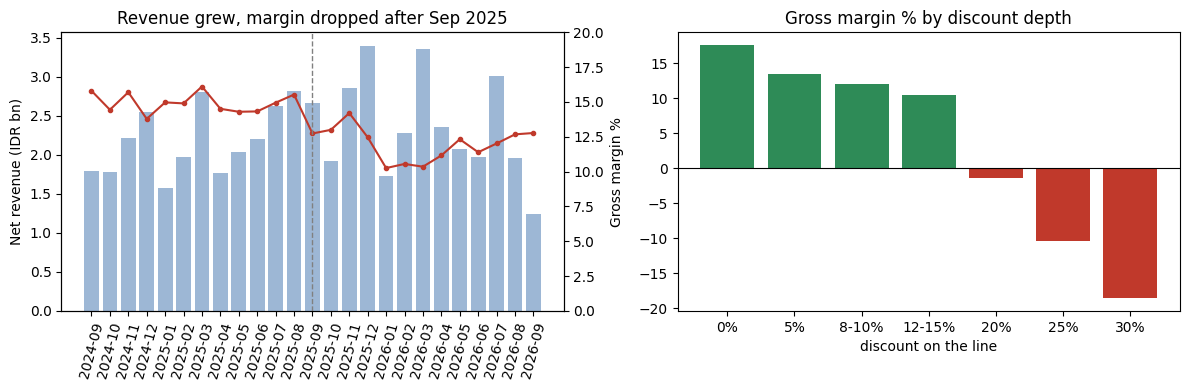

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
m = monthly.copy()
axes[0].bar(m.index, m.net_revenue / 1e9, color="#9db7d5"); axes[0].set_ylabel("Net revenue (IDR bn)"); axes[0].tick_params(axis="x", rotation=75)
ax2 = axes[0].twinx(); ax2.plot(m.index, m.margin_pct, color="#c0392b", marker="o", ms=3); ax2.set_ylim(0, 20); ax2.set_ylabel("Gross margin %")
ax2.axvline("2025-09", color="grey", ls="--", lw=1); axes[0].set_title("Revenue grew, margin dropped after Sep 2025")
b = by_band.reset_index()
axes[1].bar(b.band.astype(str), b.margin_pct, color=["#2e8b57" if v >= 0 else "#c0392b" for v in b.margin_pct]); axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Gross margin % by discount depth"); axes[1].set_xlabel("discount on the line")
plt.tight_layout(); plt.show()

In [39]:
# Save deliverables (dates written as yyyy-mm-dd)
clean.to_csv(OUT_DIR / "sales_transactions_clean.csv", index=False, date_format="%Y-%m-%d")
a.to_csv(OUT_DIR / "sales_transactions_analysis_ready.csv", index=False, date_format="%Y-%m-%d")
monthly.reset_index().to_csv(OUT_DIR / "summary_monthly.csv", index=False)
region_category.to_csv(OUT_DIR / "summary_region_category.csv", index=False)
top10.to_csv(OUT_DIR / "summary_top10_customers.csv", index=False)
print(sorted(p.name for p in OUT_DIR.iterdir()), "| sample dates:", clean["order_date"].dt.strftime("%Y-%m-%d").head(2).tolist())

['cleaning_audit_log.csv', 'removed_rows.csv', 'sales_transactions_analysis_ready.csv', 'sales_transactions_clean.csv', 'summary_monthly.csv', 'summary_region_category.csv', 'summary_top10_customers.csv'] | sample dates: ['2024-09-01', '2024-09-01']


## 7. Recommendations
1. **Discount floor by category.** Tidak diperbolehkan memberikan diskon yang membuat harga jual berada di bawah harga pokok tanpa persetujuan. *Breakeven* tercapai pada tingkat diskon sekitar 9–10% untuk laptop dan 11% untuk ponsel pintar; margin laba menjadi −1,4% / −10,4% / −18,6% pada tingkat diskon masing-masing 20% ​​/ 25% / 30%. Membatasi diskon besar (di atas 10%) akan menambah laba kotor sekitar Rp0,75 miliar (+21%) dengan asumsi volume penjualan tetap stabil. Angka ini merupakan batas atas, sehingga perlu diuji terlebih dahulu.
2. **Review the Online promotion.** Sekitar sepertiga dari lini produk online memiliki tingkat diskon 20–30%, namun pendapatan online justru stagnan (−0,5%) dengan penurunan laba kotor sebesar 55%. Sebaliknya, penjualan offline mencatat pertumbuhan pendapatan sebesar +21,7% tanpa hampir ada diskon yang besar.
3. **Review pricing authority of SR07-SR09 (Jawa Timur)** Satu-satunya perwakilan penjualan offline yang memberikan diskon ≥ 20%, inilah alasan mengapa Jawa Timur memiliki margin regional terendah (11,7%).
4. **Report margin, not only revenue.** Jika hanya melihat revenue, tahun ini tampak baik (+13%), namun profit justru turun 9,6%.
5. **Confirm the 8 quarantined Retail lines** (senilai Rp4,0 miliar, termasuk satu lini senilai Rp1,7 miliar) lini ini akan mengubah net profit sebesar 7%.
6. **Fix data capture at the source:** menggunakan format tanggal dan satuan currency yang sama, diskon dinyatakan dalam bentuk pecahan, gunakan `order_id` unik dengan pemeriksaan duplikasi saat pemuatan data, sediakan tabel referensi untuk region/kategori, data uji tidak disertakan dalam ekspor, kolom harga pokok (*cost*) wajib diisi, serta gunakan data induk pelanggan (*customer master*).

**Assumptions:** Format dd/mm/yyyy menunjukkan tanggal di depan, baris dengan nilai 1/1000 dari harga daftar dinyatakan dalam ribuan IDR, barang return membatalkan seluruh entri asli dan dicatat pada bulan terjadinya pengembalian, jika data biaya tidak tersedia, digunakan nilai median per unit untuk produk tersebut pada tahun yang sama. **Limits:** hanya mencakup dua siklus seasonal, data untuk September 2026 bersifat partial, gross margin dihitung hanya berdasarkan Harga Pokok Penjualan (COGS) yang disediakan.